# 03 — Chapman-Shaoxing: `500 Hz` Waveform Integrity, `50 Hz` Mains Spectra & `NeuroKit2` Validation

Stratified `600`-record `500 Hz` waveform audit across Chapman-Shaoxing (China = `50 Hz` powerline mains):
- Automated check for `NaN`/`Inf`, flatline leads, `>10 mV` spikes, and Einthoven limb-lead physics.
- `500 Hz` Welch PSD (`50 Hz` mains check) and `NeuroKit2` `500 Hz` HR / `CV_RR` cross-check against `SR`, `SB`, `ST`, and `AFIB`.

Scanned 600 records @ 500 Hz -> NaN: 0 | flatline: 18 | >10 mV: 12 | median Einthoven: 0.50 µV


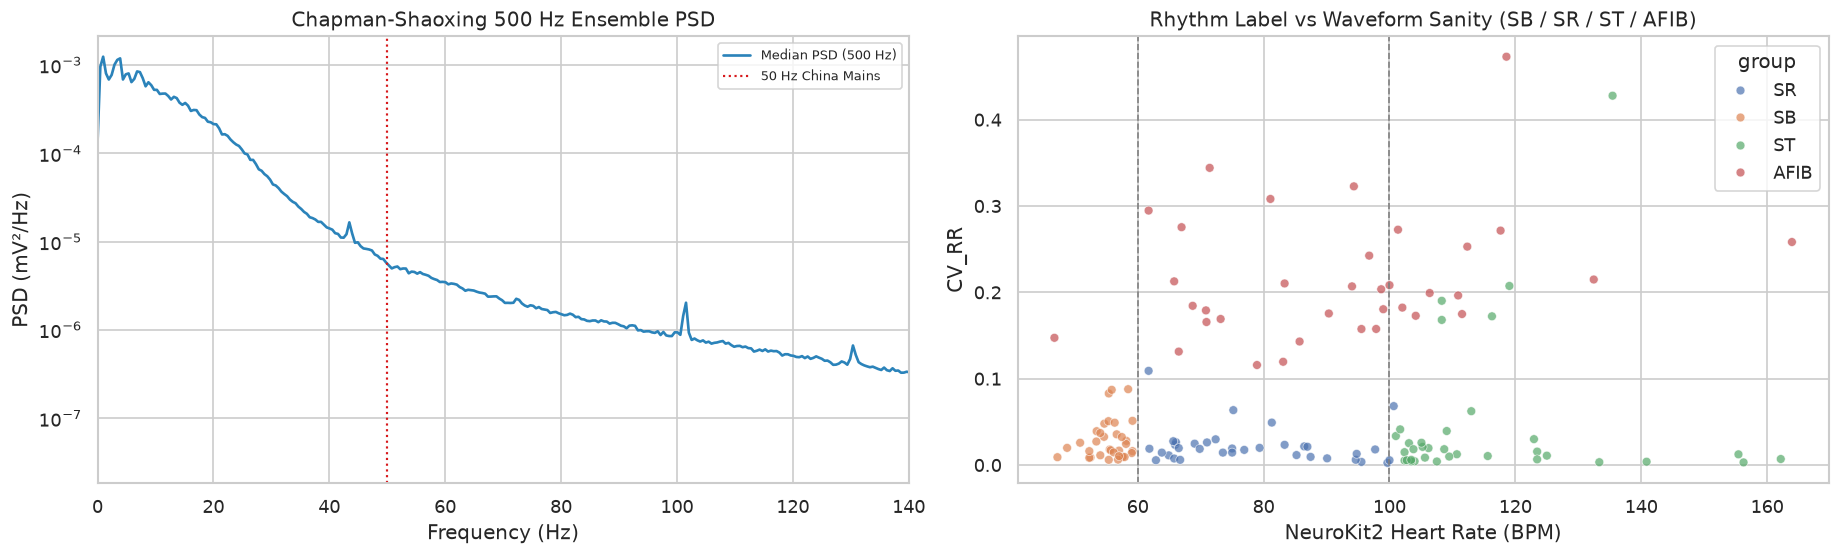

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "chapman_shaoxing" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate chapman_shaoxing/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from chapman_shaoxing import ChapmanShaoxingDataset

CHAPMAN_DIR = REPO_ROOT / "chapman_shaoxing"
DATA_DIR = CHAPMAN_DIR / "data"
QUALITY_DIR = CHAPMAN_DIR / "quality"
LEADS = ChapmanShaoxingDataset.LEADS

df = pd.read_csv(QUALITY_DIR / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")

from concurrent.futures import ThreadPoolExecutor
from scipy import signal as sp_signal
import neurokit2 as nk

valid_df = df[df["err_file_missing_or_corrupt"] == 0]
rng = np.random.default_rng(42)
scan_ids = rng.choice(valid_df.index.to_numpy(), size=min(600, len(valid_df)), replace=False)

def scan_one(rid: str):
    sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rid, "record_path"]))
    has_nan = bool(np.isnan(sig).any() or np.isinf(sig).any())
    s = np.nan_to_num(sig)
    min_std = float(s.std(axis=0).min())
    max_abs = float(np.abs(s).max())
    einth = float(np.sqrt(np.mean((s[:, 1] - (s[:, 0] + s[:, 2])) ** 2)))
    _, pxx = sp_signal.welch(s[:, 1], fs=500.0, nperseg=1024)
    return has_nan, min_std < 0.005, max_abs > 10.0, einth * 1000.0, pxx

with ThreadPoolExecutor(max_workers=16) as pool:
    res = list(pool.map(scan_one, scan_ids))

qdf = pd.DataFrame([(r[0], r[1], r[2], r[3]) for r in res], columns=["has_nan", "flatline", "gt10mv", "einth_uV"])
psds = np.vstack([r[4] for r in res])
print(f"Scanned {len(qdf)} records @ 500 Hz -> NaN: {qdf['has_nan'].sum()} | flatline: {qdf['flatline'].sum()} | >10 mV: {qdf['gt10mv'].sum()} | median Einthoven: {qdf['einth_uV'].median():.2f} µV")

# NeuroKit2 HR sanity across SR, SB, ST, AFIB (35 each)
hr_rows = []
for grp, code_str in [("SR", "426783006"), ("SB", "426177001"), ("ST", "427084000"), ("AFIB", "164889003")]:
    pool_ids = valid_df.index[valid_df["snomed_codes"].str.contains(code_str)]
    for rid in rng.choice(pool_ids.to_numpy(), size=min(35, len(pool_ids)), replace=False):
        sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rid, "record_path"]))
        w2 = np.nan_to_num(sig[:, 1])
        try:
            cln = nk.ecg_clean(w2, sampling_rate=500, method="neurokit")
            _, ri = nk.ecg_peaks(cln, sampling_rate=500, correct_artifacts=False)
            rp = np.asarray(ri.get("ECG_R_Peaks", []), dtype=int)
            if len(rp) >= 4:
                rr = np.diff(rp) / 500.0
                hr_rows.append({"group": grp, "hr_bpm": 60.0 / np.median(rr), "cv_rr": np.std(rr) / (np.mean(rr) + 1e-8)})
        except Exception:
            pass

hr_df = pd.DataFrame(hr_rows)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))
f500 = np.linspace(0, 250, psds.shape[1])
axes[0].semilogy(f500, np.median(psds, axis=0), color="#2b83ba", lw=1.6, label="Median PSD (500 Hz)")
axes[0].axvline(50, color="#d7191c", ls=":", lw=1.3, label="50 Hz China Mains")
axes[0].set_xlim(0, 140); axes[0].set_xlabel("Frequency (Hz)"); axes[0].set_ylabel("PSD (mV²/Hz)")
axes[0].set_title("Chapman-Shaoxing 500 Hz Ensemble PSD"); axes[0].legend(fontsize=8)

sns.scatterplot(data=hr_df[hr_df["cv_rr"] < 0.6], x="hr_bpm", y="cv_rr", hue="group", s=28, alpha=0.7, ax=axes[1])
axes[1].axvline(60, color="gray", ls="--", lw=1); axes[1].axvline(100, color="gray", ls="--", lw=1)
axes[1].set_xlabel("NeuroKit2 Heart Rate (BPM)"); axes[1].set_ylabel("CV_RR")
axes[1].set_title("Rhythm Label vs Waveform Sanity (SB / SR / ST / AFIB)")

plt.tight_layout()
plt.show()